# BUT PPG 품질 분류 — Random Forest 수정본

[검토한 원본 Colab](https://colab.research.google.com/drive/1Tlr1TGSt2J4aG3Utqewm_7MxrKKo16ak?usp=sharing)을 바탕으로 구성했습니다. 원본 Drive 문서를 덮어쓴 파일이 아닙니다.

구형 BUT `(1,300)` 읽기, 이름으로 빨강 채널 선택, 캐시 검증, 동일 전처리, 사람별 분할/5-fold 평가, 모델 저장, 외부 CSV 예측을 포함합니다. 모델은 기존과 같은 Random Forest입니다.
이 버전은 **재학습이 필요**합니다. 원본의 0.7319 / 0.7707 수치는 이전 모델 결과이며 이 파일의 성능이 아닙니다. 아직 새 모델의 전체 학습 결과를 넣지 않았습니다.

Colab `파일 → 노트북 업로드`에서 이 파일을 열고 위에서부터 실행하세요. CPU로 실행할 수 있습니다.
품질 1=심박수 추정에 좋은 PPG, 0=나쁜 PPG. AF/정상 진단 모델이 아닙니다.


In [1]:
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
    'numpy>=2,<3','scipy>=1.13,<2','pandas>=2.2,<4','scikit-learn>=1.5,<2',
    'wfdb>=4.1,<5','matplotlib>=3.8,<4','joblib>=1.3,<2','requests>=2.31,<3'], check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'numpy>=2,<3', 'scipy>=1.13,<2', 'pandas>=2.2,<4', 'scikit-learn>=1.5,<2', 'wfdb>=4.1,<5', 'matplotlib>=3.8,<4', 'joblib>=1.3,<2', 'requests>=2.31,<3'], returncode=0)

## 1. 공통 코드

이 셀은 학습과 외부 예측 양쪽에서 사용합니다. 기존 10개 특징을 유지합니다. 외부 fs가 다르면 anti-alias 리샘플링 후 BUT와 동일한 30 Hz로 특징을 계산합니다.
결측 10% 초과·0.2초 초과 결측 구간·끝점 결측은 명시적으로 거부합니다. 이 조건으로 제외된 데이터는 보고서에 기록합니다.


In [2]:
"""Shared training/inference functions for the corrected BUT Random Forest notebook."""
from pathlib import Path
import hashlib
import json
import math
from fractions import Fraction

import joblib
import numpy as np
import pandas as pd
import wfdb
from scipy.signal import butter, sosfiltfilt, find_peaks, welch, resample_poly
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (balanced_accuracy_score, classification_report,
    confusion_matrix, roc_auc_score, average_precision_score)

PIPELINE_VERSION = 'but-rf-quality-v2.2'
CONFIG = {'version': PIPELINE_VERSION, 'fs': 30, 'seconds': 10,
          'bandpass': [0.5, 5.0], 'filter_order': 3,
          'max_missing_fraction': 0.1, 'max_gap_seconds': 0.2,
          'normalization': 'filtered median/std', 'channel': 'PPG_R'}
FEATURES = ['finite_ratio', 'raw_std', 'raw_range', 'filtered_std',
            'difference_std', 'peak_count', 'peak_rate_bpm', 'interval_cv',
            'prominence_cv', 'pulse_power_ratio']


def read_but_red(record):
    values = np.asarray(record.p_signal, dtype=float)
    if not np.isclose(record.fs, 30):
        raise ValueError(f'BUT fs must be 30 Hz, got {record.fs}')
    if values.shape == (1, 300):
        return values.reshape(300), 'legacy_1x300'
    # Some wfdb versions parse the dotted "a.u." unit as part of sig_name.
    # The exact final token remains PPG_R/G/B; gains/baselines are still parsed.
    names = [str(name).split()[-1] if str(name).split() else ''
             for name in (record.sig_name or [])]
    if values.ndim == 2 and values.shape[0] == 300 and names.count('PPG_R') == 1:
        return values[:, names.index('PPG_R')], 'PPG_R'
    raise ValueError(f'Unsupported BUT shape/channel: {values.shape}, {names[:3]}')


def prepare_window(signal, fs):
    x = np.asarray(signal, dtype=float)
    if x.ndim != 1:
        raise ValueError('Select exactly one PPG channel; input must be 1-D.')
    fs = float(fs)
    if not np.isfinite(fs) or fs < 12:
        raise ValueError('fs must be finite and >=12 Hz for the fixed 0.5–5 Hz filter.')
    n = fs * CONFIG['seconds']
    if not np.isclose(n, round(n)) or len(x) != round(n):
        raise ValueError(f'Exactly 10 seconds required: expected {n} samples, got {len(x)}.')
    valid = np.isfinite(x)
    finite_ratio = float(valid.mean())
    if finite_ratio < 1 - CONFIG['max_missing_fraction']:
        raise ValueError('More than 10% of samples are missing/nonfinite.')
    if not valid[0] or not valid[-1]:
        raise ValueError('Missing endpoint samples; extrapolation is not permitted.')
    padded = np.r_[False, ~valid, False].astype(int)
    starts = np.flatnonzero(np.diff(padded) == 1)
    ends = np.flatnonzero(np.diff(padded) == -1)
    if len(starts) and (ends - starts).max() / fs > CONFIG['max_gap_seconds']:
        raise ValueError('Missing-data gap exceeds 0.2 seconds.')
    if not valid.all():
        idx = np.arange(len(x))
        x = np.interp(idx, idx[valid], x[valid])
    if fs != CONFIG['fs']:
        ratio = Fraction(CONFIG['fs'] / fs).limit_denominator(10000)
        if not np.isclose(float(ratio), CONFIG['fs'] / fs, rtol=1e-8):
            raise ValueError('Sampling-rate ratio cannot be represented accurately.')
        dc = x.mean()
        x = resample_poly(x-dc, ratio.numerator, ratio.denominator, padtype='line') + dc
    if x.shape != (300,) or not np.isfinite(x).all():
        raise ValueError('Resampling must produce 300 finite samples.')
    return x, finite_ratio


def extract_features(signal, fs):
    x, finite_ratio = prepare_window(signal, fs)
    fs = CONFIG['fs']
    sos = butter(CONFIG['filter_order'], CONFIG['bandpass'], btype='bandpass', fs=fs, output='sos')
    filtered = sosfiltfilt(sos, x - x.mean())
    z = (filtered - np.median(filtered)) / (np.std(filtered) + 1e-8)
    peaks, props = find_peaks(z, distance=max(1, int(fs*60/180)), prominence=.35)
    intervals = np.diff(peaks) / fs
    interval_cv = float(intervals.std()/(intervals.mean()+1e-8)) if len(peaks) >= 3 else np.nan
    prominence = props['prominences']
    prominence_cv = float(prominence.std()/(prominence.mean()+1e-8)) if len(peaks) >= 3 else np.nan
    freqs, power = welch(z, fs=fs, nperseg=240)
    def band(lo, hi):
        mask = (freqs >= lo) & (freqs < hi)
        return float(np.trapezoid(power[mask], freqs[mask])) if mask.sum() >= 2 else 0.
    return dict(finite_ratio=finite_ratio, raw_std=float(x.std()), raw_range=float(np.ptp(x)),
        filtered_std=float(filtered.std()), difference_std=float(np.diff(z).std()),
        peak_count=int(len(peaks)), peak_rate_bpm=float(len(peaks)*6),
        interval_cv=interval_cv, prominence_cv=prominence_cv,
        pulse_power_ratio=band(.7, 3)/(band(.5, 5)+1e-8))


def file_sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()


def build_but_features(root, cache_dir):
    root, cache_dir = Path(root), Path(cache_dir)
    labels = pd.read_csv(root/'quality-hr-ann.csv', dtype={'ID': str})
    if list(labels.columns) != ['ID','Quality','HR']:
        raise ValueError('Expected BUT CSV columns ID,Quality,HR.')
    if (len(labels) != 3888 or labels.ID.duplicated().any()
        or not labels.ID.str.fullmatch(r'\d{6}').all() or not labels.Quality.isin([0,1]).all()):
        raise ValueError('Expected 3,888 unique six-digit IDs and binary labels.')
    paths = [root/f'{rid}/{rid}_PPG.{ext}' for rid in labels.ID for ext in ['hea','dat']]
    missing = [str(p) for p in paths if not p.is_file()]
    if missing:
        raise FileNotFoundError(f'{len(missing)} missing waveform files: {missing[:5]}')
    fingerprint = hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode())
    for path in [root/'quality-hr-ann.csv', *paths]:
        fingerprint.update(str(path.relative_to(root)).encode())
        fingerprint.update(file_sha(path).encode())
    key = fingerprint.hexdigest()
    cache_dir.mkdir(parents=True, exist_ok=True)
    cache = cache_dir/f'{PIPELINE_VERSION}_{key[:16]}.csv'
    audit_path = cache.with_suffix('.json')
    if cache.exists() and audit_path.exists():
        audit = json.loads(audit_path.read_text())
        if audit.get('cache_sha256') == file_sha(cache) and audit.get('fingerprint') == key:
            print('Verified feature cache:', cache.name)
            return pd.read_csv(cache, dtype={'record_id':str,'subject_id':str}), audit
    rows, errors, layouts = [], [], {}
    for i, row in enumerate(labels.itertuples(index=False), 1):
        try:
            rec = wfdb.rdrecord(str(root/f'{row.ID}/{row.ID}_PPG'))
            signal, layout = read_but_red(rec)
            features = extract_features(signal, rec.fs)
            rows.append(dict(record_id=row.ID, subject_id=row.ID[:3], quality=int(row.Quality), **features))
            layouts[layout] = layouts.get(layout, 0) + 1
        except (ValueError, OSError, IndexError) as exc:
            errors.append({'record_id':row.ID, 'reason':str(exc)})
        if i % 500 == 0 or i == len(labels):
            print(f'{i}/{len(labels)} records; accepted={len(rows)}, excluded={len(errors)}', flush=True)
    frame = pd.DataFrame(rows)
    if frame.empty:
        raise ValueError(f'No valid BUT records: {errors[:3]}')
    frame.to_csv(cache, index=False)
    audit = dict(fingerprint=key, cache_sha256=file_sha(cache), config=CONFIG,
        total=3888, accepted=len(rows), subjects=int(frame.subject_id.nunique()), layouts=layouts, excluded=errors)
    audit_path.write_text(json.dumps(audit, indent=2), encoding='utf-8')
    return frame, audit


def grouped_split(frame, seed=42):
    groups = frame.subject_id.to_numpy()
    tr, rest = next(GroupShuffleSplit(n_splits=1, test_size=.30, random_state=seed).split(frame, groups=groups))
    va, te = next(GroupShuffleSplit(n_splits=1, test_size=.50, random_state=seed+1).split(frame.iloc[rest], groups=groups[rest]))
    result = {'train':tr, 'validation':rest[va], 'test':rest[te]}
    for name, ids in result.items():
        if frame.iloc[ids].quality.nunique() != 2:
            raise ValueError(f'{name} lacks both classes. Review the predeclared split protocol.')
    for left, right in [('train','validation'),('train','test'),('validation','test')]:
        assert set(groups[result[left]]).isdisjoint(groups[result[right]])
    return result


def new_model(seed=42):
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True),
        RandomForestClassifier(n_estimators=400, min_samples_leaf=3,
                               class_weight='balanced_subsample', random_state=seed, n_jobs=-1))


def choose_threshold(y, score):
    y, score = np.asarray(y, int), np.asarray(score, float)
    if set(np.unique(y)) != {0,1} or not np.isfinite(score).all():
        raise ValueError('Threshold selection needs both classes and finite scores.')
    thresholds = np.unique(np.r_[0., .5, score, np.nextafter(score.max(), np.inf)])
    values = np.array([balanced_accuracy_score(y, score >= t) for t in thresholds])
    best = thresholds[np.isclose(values, values.max(), atol=1e-12, rtol=0)]
    return float(best[np.lexsort((best, np.abs(best-.5)))[0]])


def metrics(y, score, threshold):
    y, score = np.asarray(y, int), np.asarray(score, float)
    prediction = (score >= threshold).astype(int)
    both = len(np.unique(y)) == 2
    return {'n':len(y), 'threshold':float(threshold),
        'balanced_accuracy':float(balanced_accuracy_score(y,prediction)) if both else None,
        'auroc':float(roc_auc_score(y,score)) if both else None,
        'auprc_good':float(average_precision_score(y,score)) if both else None,
        'confusion_matrix':confusion_matrix(y,prediction,labels=[0,1]).tolist(),
        'classes':classification_report(y,prediction,labels=[0,1],target_names=['bad','good'],
                                         output_dict=True,zero_division=0)}


def train_holdout(frame, output):
    output = Path(output); output.mkdir(parents=True, exist_ok=True)
    split = grouped_split(frame)
    train, val, test = [frame.iloc[split[s]] for s in ['train','validation','test']]
    model = new_model().fit(train[FEATURES], train.quality)
    threshold = choose_threshold(val.quality, model.predict_proba(val[FEATURES])[:,1])
    probabilities = model.predict_proba(test[FEATURES])[:,1]
    bundle = dict(model=model, feature_cols=FEATURES, threshold=threshold, config=CONFIG,
        label_meaning={0:'bad quality for HR estimation',1:'good quality for HR estimation'},
        seed=42, threshold_source='validation subjects only')
    joblib.dump(bundle, output/'butppg_quality_rf.joblib')
    restored = load_bundle(output/'butppg_quality_rf.joblib')
    np.testing.assert_allclose(restored['model'].predict_proba(test[FEATURES])[:,1], probabilities)
    scores = {'model':metrics(test.quality, probabilities, threshold),
              'always_bad':metrics(test.quality, np.zeros(len(test)), .5)}
    (output/'metrics.json').write_text(json.dumps(scores,indent=2), encoding='utf-8')
    split_table = frame[['record_id','subject_id','quality']].copy()
    split_table['split'] = ''
    for name, ids in split.items():
        split_table.loc[split_table.index[ids], 'split'] = name
        part = frame.iloc[ids]
        print(name, 'records=',len(part),'subjects=',part.subject_id.nunique(),'labels=',part.quality.value_counts().to_dict())
    split_table.to_csv(output/'split.csv', index=False)
    predictions = test[['record_id','subject_id','quality']].copy()
    predictions['good_score'] = probabilities
    predictions['prediction'] = (probabilities >= threshold).astype(int)
    predictions.to_csv(output/'test_predictions.csv', index=False)
    return bundle, scores, predictions


def grouped_cv(frame):
    """Outer test never chooses a threshold. Descriptive 5-fold robustness check."""
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    reports, predictions = [], []
    for fold, (development, test) in enumerate(splitter.split(frame,frame.quality,frame.subject_id)):
        dev = frame.iloc[development]
        tr, va = next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=100+fold).split(dev,groups=dev.subject_id))
        training, validation, testing = dev.iloc[tr], dev.iloc[va], frame.iloc[test]
        for part in [training, validation, testing]:
            if part.quality.nunique() != 2:
                raise ValueError(f'Fold {fold} has a single-class subset; no silent seed search.')
        model = new_model(42+fold).fit(training[FEATURES],training.quality)
        threshold = choose_threshold(validation.quality,model.predict_proba(validation[FEATURES])[:,1])
        score = model.predict_proba(testing[FEATURES])[:,1]
        report = metrics(testing.quality,score,threshold)
        reports.append(dict(fold=fold,**{k:report[k] for k in ['n','threshold','balanced_accuracy','auroc','auprc_good']}))
        pred = testing[['record_id','subject_id','quality']].copy()
        pred['fold'], pred['good_score'], pred['threshold'] = fold, score, threshold
        predictions.append(pred)
        print('CV fold',fold,reports[-1],flush=True)
    return pd.DataFrame(reports), pd.concat(predictions,ignore_index=True)


def load_bundle(path):
    bundle = joblib.load(path)  # Load only your own trusted model file.
    if bundle.get('config') != CONFIG or bundle.get('feature_cols') != FEATURES:
        raise ValueError('Old/incompatible model: retrain with this notebook before inference.')
    return bundle


def external_windows(signal, fs):
    fs = float(fs)
    if not np.isfinite(fs) or fs < 12 or not np.isclose(fs*10, round(fs*10)):
        raise ValueError('Provide the actual finite sampling rate >=12 Hz.')
    x = np.asarray(signal,float)
    if x.ndim != 1:
        raise ValueError('External PPG must be one channel.')
    width = int(round(fs*10))
    if len(x) < width:
        raise ValueError('Recording is shorter than 10 seconds; no padding is used.')
    return [(start/fs,x[start:start+width]) for start in range(0,len(x)-width+1,width)], (len(x)%width)/fs


def predict_external(bundle, info, root, output):
    root, output = Path(root), Path(output)
    output.mkdir(parents=True,exist_ok=True)
    if bundle.get('config') != CONFIG:
        raise ValueError('Incompatible preprocessing config.')
    rows, errors, audits = [], [], []
    for item in info:
        filename = item['filename']
        try:
            if Path(filename).name != filename:
                raise ValueError('Use a filename only, without directories.')
            label = item.get('quality')
            if label is not None and label not in [0,1]:
                raise ValueError('quality must be 0,1 or None.')
            fs = float(item['fs'])
            table = pd.read_csv(root/filename)
            column = item.get('column','ppg')
            if column not in table:
                raise ValueError(f'Missing {column!r} column: {list(table.columns)}')
            signal = pd.to_numeric(table[column],errors='coerce').to_numpy()
            windows, tail = external_windows(signal,fs)
            if label is not None and len(windows) > 1:
                raise ValueError('For labeled evaluation, supply one 10-second window per CSV; long files use quality=None.')
            audits.append(dict(filename=filename,fs=fs,windows=len(windows),discarded_tail_seconds=tail))
            for start, raw in windows:
                try:
                    features = pd.DataFrame([extract_features(raw,fs)], columns=FEATURES)
                    score = float(bundle['model'].predict_proba(features)[0,1])
                    rows.append(dict(filename=filename,start_seconds=start,quality=label,good_score=score,
                        predicted_quality=int(score>=bundle['threshold']),status='ok',reason=''))
                except ValueError as exc:
                    rows.append(dict(filename=filename,start_seconds=start,quality=label,good_score=np.nan,
                        predicted_quality=pd.NA,status='unusable_input',reason=str(exc)))
        except (OSError,ValueError,TypeError,KeyError,pd.errors.ParserError) as exc:
            errors.append(dict(filename=filename,reason=str(exc)))
    result = pd.DataFrame(rows,columns=['filename','start_seconds','quality','good_score','predicted_quality','status','reason'])
    result.to_csv(output/'external_predictions.csv',index=False)
    (output/'external_audit.json').write_text(json.dumps({'files':audits,'file_errors':errors,
        'unusable_windows':int((result.status!='ok').sum()),'threshold':bundle['threshold']},indent=2),encoding='utf-8')
    labeled = result[(result.status=='ok') & result.quality.notna()]
    if len(labeled):
        report = metrics(labeled.quality.astype(int),labeled.good_score,bundle['threshold'])
        report['scope'] = 'User-provided independent quality labels; valid windows only. See exclusions in audit.'
        (output/'external_metrics.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
        print(json.dumps(report,indent=2))
    else:
        print('No independent quality labels: predictions only; no accuracy/F1 calculated.')
    if errors:
        print('File errors:', errors)
    return result


## 2. 실행 모드와 저장 폴더

처음에는 `TRAIN=True`. 이미 이 수정본으로 저장한 모델을 재사용할 때에는 `TRAIN=False`로 변경합니다.
Drive를 사용하려면 `SAVE_TO_DRIVE=True`로 바꾸세요. False일 때 결과는 임시 Colab 저장소에 있으므로 마지막 ZIP 다운로드 셀에서 내려받으세요.


In [3]:
from datetime import datetime, timezone
import importlib.metadata
import shutil
from IPython.display import display
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

TRAIN = True
RUN_CV = True
SAVE_TO_DRIVE = False
EXISTING_MODEL = '/content/butppg_quality_rf.joblib'  # TRAIN=False일 때 이 수정본의 모델 경로
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    SAVE_ROOT = Path('/content/drive/MyDrive/capdyssey_ppg_quality')
else:
    SAVE_ROOT = Path('/content/ppg_quality_results')
RUN = SAVE_ROOT/datetime.now(timezone.utc).strftime('rf_%Y%m%dT%H%M%S_%fZ')
RUN.mkdir(parents=True,exist_ok=False)
REPO = Path('/content/capdyssey')
DATA_ROOT = REPO/'data/raw/but'
CACHE_DIR = Path('/content/but_rf_verified_cache')
print('결과 폴더:', RUN)
environment = {name:importlib.metadata.version(name) for name in
               ['numpy','scipy','pandas','scikit-learn','wfdb','joblib']}
(RUN/'environment.json').write_text(json.dumps(environment,indent=2),encoding='utf-8')
(RUN/'preprocessing.json').write_text(json.dumps(CONFIG,indent=2),encoding='utf-8')


결과 폴더: /content/ppg_quality_results/rf_20261011T134527_588679Z


247

## 3. BUT 데이터 확보

기존 `/content/capdyssey/data/raw/but`를 그대로 사용할 수 있습니다. 다운로드 도구는 원본 checksum을 확인하고 일치하는 파일은 재사용합니다.
약 2만 7천 개 파일을 확인하므로 첫 다운로드는 시간이 걸릴 수 있습니다.


In [4]:
if TRAIN:
    if not (REPO/'.git').exists():
        subprocess.run(['git','clone','https://github.com/dung-ho03/capdyssey.git',str(REPO)],check=True)
    if not (REPO/'scripts/download_data.py').exists():
        raise FileNotFoundError('capdyssey/scripts/download_data.py가 없습니다. REPO 경로를 확인하세요.')
    subprocess.run([sys.executable,str(REPO/'scripts/download_data.py'),'but','--workers','8'],check=True)
    commit = subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD'],text=True).strip()
    (RUN/'data_source_commit.txt').write_text(commit,encoding='utf-8')


## 4. 특징 추출과 데이터 감사

이전 `butppg_features_local.csv`는 사용하지 않습니다. 새 캐시는 원본 .hea/.dat 및 라벨의 해시와 전처리 버전으로 구분합니다.
구형 자료 48개는 100–111번 피험자의 기록입니다. 원본에서 빠져 학습 피험자가 50명에서 38명으로 줄었던 부분을 복구합니다.
다른 문제가 있는 파일은 제외 이유를 확인하세요. 단순히 3,888개라고 가정하고 성능을 보고하지 않습니다.


In [5]:
if TRAIN:
    features_df, audit = build_but_features(DATA_ROOT,CACHE_DIR)
    (RUN/'data_audit.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
    display(pd.DataFrame([{k:v for k,v in audit.items() if k not in ['excluded','config']}]))
    print('제외 기록:',audit['excluded'])
    display(features_df.head())
    print('라벨 분포:',features_df.quality.value_counts().to_dict())


500/3888 records; accepted=500, excluded=0
1000/3888 records; accepted=1000, excluded=0
1500/3888 records; accepted=1500, excluded=0
2000/3888 records; accepted=2000, excluded=0
2500/3888 records; accepted=2500, excluded=0
3000/3888 records; accepted=3000, excluded=0
3500/3888 records; accepted=3500, excluded=0
3888/3888 records; accepted=3888, excluded=0


,fingerprint,cache_sha256,total,accepted,subjects,layouts
0,d776b2f6a06a4545c4900c639ad7709fe8c55472c907a4...,2645bf9677b21bbbdb7a19061a6717d5f362182f112ddb...,3888,3888,50,"{'legacy_1x300': 48, 'PPG_R': 3840}"


제외 기록: []


,record_id,subject_id,quality,finite_ratio,raw_std,raw_range,filtered_std,difference_std,peak_count,peak_rate_bpm,interval_cv,prominence_cv,pulse_power_ratio
0,100001,100,1,1.0,0.163361,0.845710,0.110976,0.471260,18,108.0,0.277506,0.515927,0.819756
1,100002,100,1,1.0,0.220934,1.128231,0.195420,0.368818,15,90.0,0.238250,0.339611,0.890611
2,100003,100,1,1.0,0.324770,1.680487,0.265146,0.428803,14,84.0,0.196513,0.377893,0.886510
3,100004,100,0,1.0,29.052874,163.552200,22.562629,0.384657,16,96.0,0.491451,0.581807,0.525005
4,101001,101,1,1.0,0.157399,0.615110,0.159459,0.274195,10,60.0,0.044141,0.119096,0.966734


라벨 분포: {0: 3058, 1: 830}


## 5. 최종 — 학습·검증·시험 및 모델 저장

사람별 약 70/15/15 분할을 고정합니다. 각 분할에는 두 클래스가 있어야 합니다. 대체값 계산은 학습 자료에만 fit하고, 임계값은 검증 사람의 balanced accuracy로 정합니다.
시험 자료를 보고 임계값이나 모델을 다시 조정하면 해당 시험 결과를 최종 독립 평가로 사용하지 마세요.
저장 파일에 모델, 임계값, 열 순서, 전처리 설정을 함께 보관합니다. 저장 직후 다시 읽어서 예측 일치를 확인합니다.


train records= 2670 subjects= 35 labels= {0: 2029, 1: 641}
validation records= 482 subjects= 7 labels= {0: 431, 1: 51}
test records= 736 subjects= 8 labels= {0: 598, 1: 138}
{
  "model": {
    "n": 736,
    "threshold": 0.28272693235193613,
    "balanced_accuracy": 0.7647714604236344,
    "auroc": 0.80712277640444,
    "auprc_good": 0.5016672060462327,
    "confusion_matrix": [
      [
        490,
        108
      ],
      [
        40,
        98
      ]
    ],
    "classes": {
      "bad": {
        "precision": 0.9245283018867925,
        "recall": 0.8193979933110368,
        "f1-score": 0.8687943262411347,
        "support": 598.0
      },
      "good": {
        "precision": 0.47572815533980584,
        "recall": 0.7101449275362319,
        "f1-score": 0.5697674418604651,
        "support": 138.0
      },
      "accuracy": 0.7989130434782609,
      "macro avg": {
        "precision": 0.7001282286132992,
        "recall": 0.7647714604236344,
        "f1-score": 0.7192808840507999

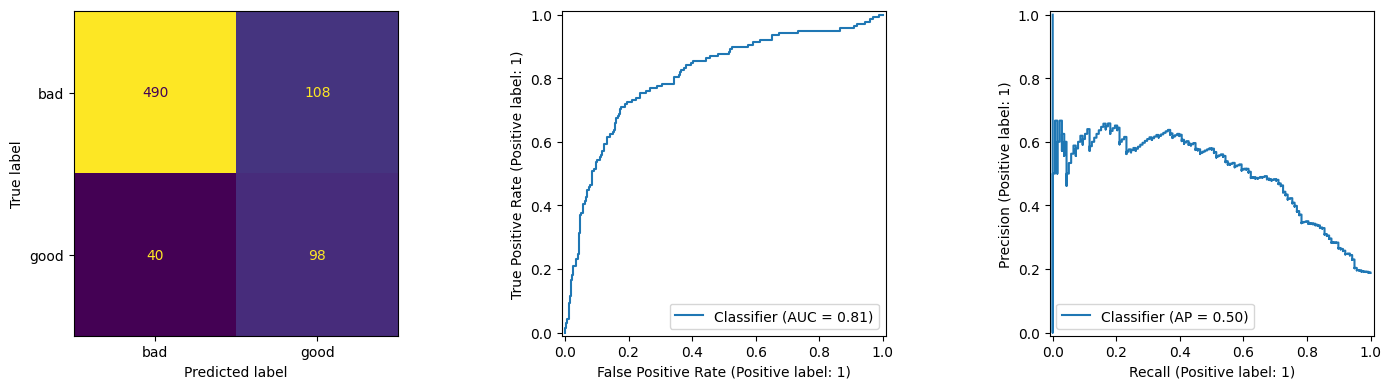

모델: /content/ppg_quality_results/rf_20261011T134527_588679Z/model/butppg_quality_rf.joblib


In [6]:
if TRAIN:
    bundle, reports, test_predictions = train_holdout(features_df,RUN/'model')
    print(json.dumps(reports,indent=2))
    fig,axes = plt.subplots(1,3,figsize=(15,4))
    ConfusionMatrixDisplay.from_predictions(test_predictions.quality,test_predictions.prediction,
        labels=[0,1],display_labels=['bad','good'],ax=axes[0],colorbar=False)
    RocCurveDisplay.from_predictions(test_predictions.quality,test_predictions.good_score,ax=axes[1])
    PrecisionRecallDisplay.from_predictions(test_predictions.quality,test_predictions.good_score,ax=axes[2])
    plt.tight_layout(); plt.savefig(RUN/'test_metrics.png',dpi=160); plt.show()
    print('모델:',RUN/'model/butppg_quality_rf.joblib')
else:
    bundle = load_bundle(EXISTING_MODEL)
    print('저장 모델 로드 완료:',EXISTING_MODEL)


## 6. 선택: 사람 단위 5-fold 평가

각 outer fold의 시험 사람을 제외한 자료에서 학습/검증을 나누고 임계값을 선택합니다. 평균과 표준편차는 분할에 따른 변동을 보여주며 95% 신뢰구간이 아닙니다.
이 평가는 데이터가 전체적으로 재사용되므로 위 holdout과 독립된 두 번째 증거로 해석하지 마세요. 비교 결과를 이용해 모델을 바꾼 뒤에는 새 외부 평가가 필요합니다.


In [7]:
if TRAIN and RUN_CV:
    cv_summary,cv_predictions = grouped_cv(features_df)
    cv_summary.to_csv(RUN/'cv_summary.csv',index=False)
    cv_predictions.to_csv(RUN/'cv_predictions.csv',index=False)
    display(cv_summary)
    display(cv_summary[['balanced_accuracy','auroc','auprc_good']].agg(['mean','std']))


CV fold 0 {'fold': 0, 'n': 498, 'threshold': 0.2712719150944147, 'balanced_accuracy': 0.7247252286265626, 'auroc': 0.7808540984981962, 'auprc_good': 0.47880558661622863}
CV fold 1 {'fold': 1, 'n': 1072, 'threshold': 0.3282128765281851, 'balanced_accuracy': 0.797389479207661, 'auroc': 0.8463019808474354, 'auprc_good': 0.6065072311675327}
CV fold 2 {'fold': 2, 'n': 586, 'threshold': 0.2504818601924174, 'balanced_accuracy': 0.7088222511951325, 'auroc': 0.7756048095031146, 'auprc_good': 0.5486849303178186}
CV fold 3 {'fold': 3, 'n': 884, 'threshold': 0.23053243910073648, 'balanced_accuracy': 0.7533058917568274, 'auroc': 0.8224039072776823, 'auprc_good': 0.6879264379544691}
CV fold 4 {'fold': 4, 'n': 848, 'threshold': 0.33511153093624396, 'balanced_accuracy': 0.7569394436923313, 'auroc': 0.8343174813491949, 'auprc_good': 0.5247345515176292}


,fold,n,threshold,balanced_accuracy,auroc,auprc_good
0,0,498,0.271272,0.724725,0.780854,0.478806
1,1,1072,0.328213,0.797389,0.846302,0.606507
2,2,586,0.250482,0.708822,0.775605,0.548685
3,3,884,0.230532,0.753306,0.822404,0.687926
4,4,848,0.335112,0.756939,0.834317,0.524735


,balanced_accuracy,auroc,auprc_good
mean,0.748236,0.811896,0.569332
std,0.033999,0.031928,0.080711


## 7. 외부 CSV 업로드 — 필요할 때만 실행

`UPLOAD_EXTERNAL=True`로 바꾼 뒤 이 셀만 실행하면 파일 선택 창이 나옵니다. 기본값은 False라 모두 실행이 업로드 대기에서 멈추지 않습니다.
CSV에는 `ppg` 열 하나와 실제 샘플 값이 있어야 합니다. 예시 텍스트를 코드 셀로 실행하지 마세요.
모델 재사용 시 자신의 `.joblib`을 Colab 파일 패널로 올리고 `EXISTING_MODEL`에 경로를 지정할 수 있습니다.


In [8]:
EXTERNAL_DIR = Path('/content/external_ppg')
EXTERNAL_DIR.mkdir(parents=True,exist_ok=True)
UPLOAD_EXTERNAL = False
if UPLOAD_EXTERNAL:
    from google.colab import files
    uploaded = files.upload()
    for filename,content in uploaded.items():
        if filename.lower().endswith('.csv'):
            (EXTERNAL_DIR/Path(filename).name).write_bytes(content)
print('CSV 파일:',[p.name for p in sorted(EXTERNAL_DIR.glob('*.csv'))])


CSV 파일: []


## 8. 외부 데이터 메타데이터

업로드 파일을 자동으로 찾습니다. **`fs=None`을 실제 Hz로 바꾼 뒤** 다음 셀을 실행하세요. 추측한 Hz를 쓰면 시간 길이·필터·특징이 달라집니다.
`quality=None`이면 예측만 합니다. 독립적으로 판정한 실제 좋은/나쁜 라벨이 있을 때만 0/1을 넣으세요. 라벨은 10초 CSV 한 개에 하나씩만 허용합니다.
긴 파일은 quality=None 상태로 10초씩 예측하며, 마지막 10초 미만 부분은 버린 길이를 감사 파일에 기록합니다.
raw_std/raw_range/filtered_std는 센서의 단위와 이득 영향을 받습니다. BUT와 다른 센서는 별도 품질 라벨로 외부 검증해야 합니다.


In [9]:
external_info = [dict(filename=p.name,fs=None,column='ppg',quality=None)
                 for p in sorted(EXTERNAL_DIR.glob('*.csv'))]
# 예: external_info[0]['fs'] = 100  # 실제 수집 주파수가 100 Hz인 경우에만
display(pd.DataFrame(external_info))


""


## 9. 외부 예측·평가

`good_score`는 모델의 점수이며 교정된 확률이 아닙니다. 임계값은 BUT 검증값으로 고정합니다.
없는 파일, 잘못된 fs, 결측·짧은 창은 오류 또는 `unusable_input`으로 기록합니다. 거부된 창을 성공한 예측처럼 세지 않습니다.
정답 없는 데이터에는 외부 정확도/F1을 출력하지 않습니다. 정답이 한 클래스뿐이면 balanced accuracy/AUROC/AUPRC는 null입니다.


In [10]:
if not external_info:
    print('외부 CSV가 없습니다. 7번에서 업로드하고 8번 fs 설정 후 실행하세요.')
elif any(item.get('fs') is None for item in external_info):
    print('8번 external_info에서 모든 파일의 실제 fs를 지정하세요.')
else:
    external_result = predict_external(bundle,external_info,EXTERNAL_DIR,RUN/'external')
    display(external_result)


외부 CSV가 없습니다. 7번에서 업로드하고 8번 fs 설정 후 실행하세요.


## 10. 저장·다운로드

모델과 지표, 분할, 데이터 감사 파일을 ZIP으로 저장합니다. 원본 PPG는 포함하지 않습니다.
재사용하려면 이 노트북과 `.joblib`을 함께 보관하세요. 본인에게 신뢰할 수 있는 모델 파일만 joblib로 읽으세요.

자료 출처: [BUT PPG 2.0.0](https://physionet.org/content/butppg/2.0.0/) · [DOI](https://doi.org/10.13026/tn53-8153) · CC BY 4.0. 발표 시 공식 페이지의 데이터 및 원 논문 인용 안내를 따르세요.


In [11]:
archive = shutil.make_archive(str(RUN),'zip',root_dir=RUN)
print('결과 폴더:',RUN)
print('ZIP:',archive)
DOWNLOAD_RESULTS = False  # 내려받으려면 True로 바꾸고 실행
if DOWNLOAD_RESULTS:
    from google.colab import files
    files.download(archive)


결과 폴더: /content/ppg_quality_results/rf_20261011T134527_588679Z
ZIP: /content/ppg_quality_results/rf_20261011T134527_588679Z.zip
